# GAM: Partial Dependence Plots

This notebook fits a Generalized Additive Model (GAM) with the `pygam` package, following the Week 6 lab, and plots the partial dependence of `final_grade_pct` on the four strongest continuous predictors. A partial dependence plot shows the effect of one predictor on the predicted grade while the others are held fixed, so a straight line means the effect is linear and a curve means it is not.

## Data preparation (copied from the main notebook)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pygam import LinearGAM, s, l, f
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error
from IPython.display import display

df = pd.read_csv('student_grade_ses_dataset.csv')
print(df.shape)

(12025, 29)


In [2]:
# 1. Cleaning duplicate rows
row_count_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"{row_count_before} rows -> {len(df)} after removing duplicates")

# 2. Set 'student_id' as the index
print(f"Column student_id uniqueness: {df['student_id'].is_unique}")
df = df.set_index('student_id', drop=True)

# TEMPORARY (same as the main notebook): drop rows with missing values until an imputation strategy is added
rows_before = len(df)
df = df.dropna()
print(f"{rows_before} rows -> {len(df)} after dropping rows with missing values")

12025 rows -> 12000 after removing duplicates
Column student_id uniqueness: True
12000 rows -> 8785 after dropping rows with missing values


In [3]:
# Income is heavily right-skewed, so use its log (same as the main notebook)
df['log_income'] = np.log(df.pop('annual_family_income_inr'))

In [4]:
# Schema Setup (same as the main notebook)
REGRESSION_TARGET = 'final_grade_pct'

CONTINUOUS_COLS = [
    'distance_to_school_km',
    'study_hours_per_week',
    'attendance_rate_pct',
    'previous_year_grade_pct',
    'log_income',
]

# Integer-coded, including 0/1 flags and the 1-5 parental involvement score
# (age and num_siblings are dropped: highly correlated with grade_level and family_size)
DISCRETE_COLS = [
    'grade_level',
    'family_size',
    'single_parent_household',
    'has_internet_access',
    'has_computer_or_laptop',
    'extra_tutoring',
    'parental_involvement_score',
]

# Categories with a natural order (lowest level first)
ORDINAL_COLUMNS = {
    'father_education_level': [
        'No Formal Education', 'Primary', 'Secondary', 'Higher Secondary',
        "Bachelor's Degree", "Master's Degree", 'Doctorate',
    ],
    'mother_education_level': [
        'No Formal Education', 'Primary', 'Secondary', 'Higher Secondary',
        "Bachelor's Degree", "Master's Degree", 'Doctorate',
    ],
    'family_income_bracket': ['Low', 'Lower-Middle', 'Middle', 'Upper-Middle', 'High'],
    'scholarship_status': ['No Scholarship', 'Partial', 'Full'],
}

# Categories with no natural order
NOMINAL_COLS = [
    'academic_year', 'gender', 'school_type', 'residence_type',
    'father_occupation', 'mother_occupation',
]

## Build the design matrix

`pygam` needs a numeric array, and each column is addressed by its position (as in the lab, where `pd.Categorical(...).codes` turns a text column into integer codes). The columns are ordered as: continuous, discrete, ordinal, nominal. Each group gets a different type of term:

| Columns | pygam term | Meaning |
|---|---|---|
| Continuous (5) | `s(j)` | A smooth spline curve, so the effect can bend |
| Discrete and ordinal | `l(j)` | A straight-line effect |
| Nominal | `f(j)` | A separate coefficient for each category |

In [5]:
ordinal_codes = pd.DataFrame({
    col: pd.Categorical(df[col], categories=levels, ordered=True).codes
    for col, levels in ORDINAL_COLUMNS.items()
}, index=df.index)

nominal_codes = pd.DataFrame({
    col: pd.Categorical(df[col]).codes for col in NOMINAL_COLS
}, index=df.index)

X_df = pd.concat([df[CONTINUOUS_COLS], df[DISCRETE_COLS], ordinal_codes, nominal_codes], axis=1)
y = df[REGRESSION_TARGET]
feature_names = list(X_df.columns)

# Column positions for each group
n_cont, n_disc, n_ord = len(CONTINUOUS_COLS), len(DISCRETE_COLS), len(ORDINAL_COLUMNS)
cont_idx = list(range(n_cont))
linear_idx = list(range(n_cont, n_cont + n_disc + n_ord))
nominal_idx = list(range(n_cont + n_disc + n_ord, X_df.shape[1]))

X_train, X_test, y_train, y_test = train_test_split(
    X_df.to_numpy(dtype=float), y.to_numpy(), test_size=0.15, random_state=0, shuffle=True
)
print('X_train:', X_train.shape, ' X_test:', X_test.shape)

X_train: (7467, 22)  X_test: (1318, 22)


## GAM with the default smoothing penalty

First fit with `lam=0.6` on every smooth term, as the lab does before tuning. `n_splines=10` matches the `GAMRegressor` in the main notebook.

In [6]:
def make_gam(lam):
    terms = s(cont_idx[0], n_splines=10, lam=lam)
    for j in cont_idx[1:]:
        terms = terms + s(j, n_splines=10, lam=lam)
    for j in linear_idx:
        terms = terms + l(j)
    for j in nominal_idx:
        terms = terms + f(j, lam=0)      # no penalty on the factor terms, as in the lab
    return LinearGAM(terms)

gam = make_gam(lam=0.6).fit(X_train, y_train)
print(f"Test RMSE (lam = 0.6): {root_mean_squared_error(y_test, gam.predict(X_test)):.3f}")

Test RMSE (lam = 0.6): 10.142


### Partial dependence plots

As in the lab, `generate_X_grid` builds a grid over one predictor, `partial_dependence` returns the curve and a 95% confidence band (red dashed), and the small ticks at the bottom show where the training data lies. The grey dotted line is the best straight line through the curve, so you can see how far the fitted curve is from linear. The table under each figure gives the slope of that line, the R² of the line against the curve, and the share of the range where the line stays inside the 95% band.

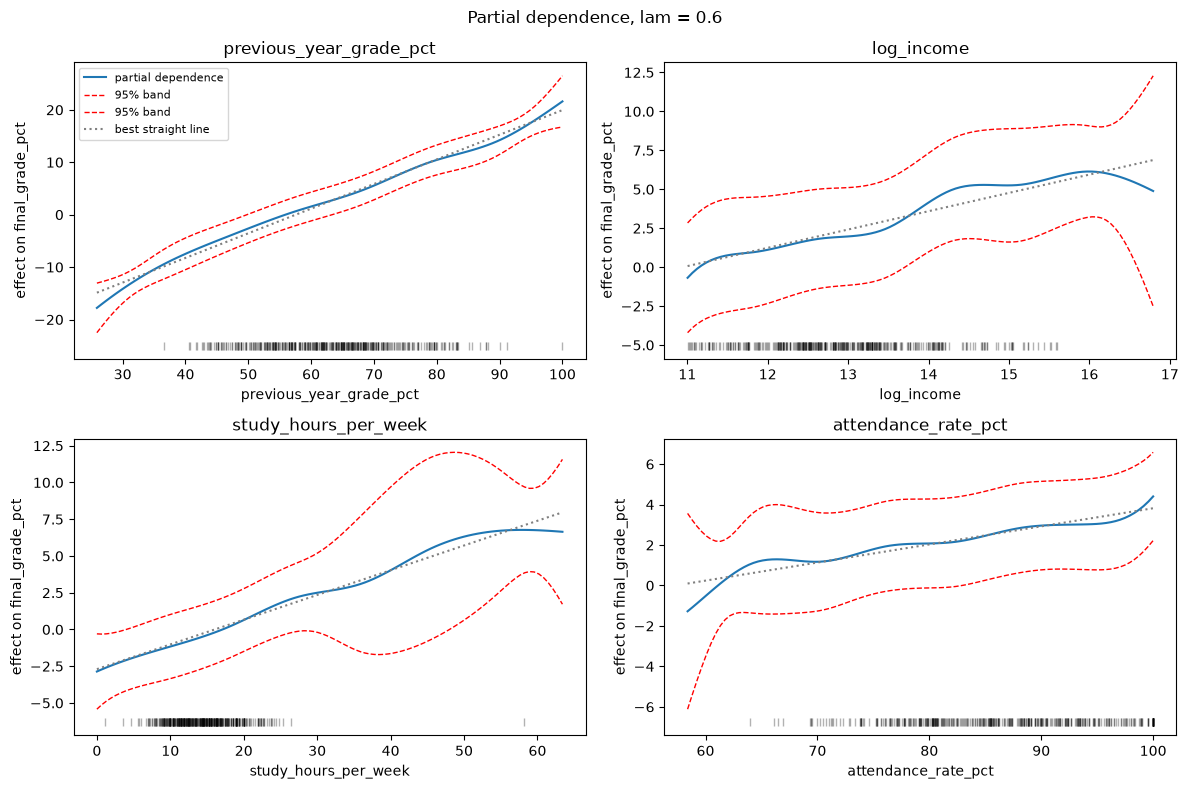

,predictor,slope of straight line,R2 of straight line vs curve,share of range with line inside 95% band
0,previous_year_grade_pct,0.470,0.993,1.0
1,log_income,1.175,0.918,1.0
2,study_hours_per_week,0.168,0.986,1.0
3,attendance_rate_pct,0.089,0.912,1.0


In [7]:
# The four strongest continuous predictors in the Lasso feature selection of the main notebook
# (distance_to_school_km was dropped by the Lasso, so it is left out of the plots)
TOP_FEATURES = ['previous_year_grade_pct', 'log_income', 'study_hours_per_week', 'attendance_rate_pct']

def plot_partial_dependence(gam, title, features=TOP_FEATURES):
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    axes = axes.flatten()
    rng = np.random.default_rng(0)
    summary = []

    for ax, name in zip(axes, features):
        j = feature_names.index(name)
        XX = gam.generate_X_grid(term=j)
        pdep, confi = gam.partial_dependence(term=j, X=XX, width=0.95)
        x = XX[:, j]

        # How close is the curve to a straight line?
        slope, intercept = np.polyfit(x, pdep, 1)
        line = slope * x + intercept
        r2_line = 1 - np.sum((pdep - line) ** 2) / np.sum((pdep - pdep.mean()) ** 2)
        inside = np.mean((line >= confi[:, 0]) & (line <= confi[:, 1]))   # share of the range where the line sits inside the 95% band

        ax.plot(x, pdep, label='partial dependence')
        ax.plot(x, confi, c='r', ls='--', lw=1, label='95% band')
        ax.plot(x, line, c='grey', ls=':', label='best straight line')

        # rug: where the training data lies
        ymin = ax.get_ylim()[0]
        sample = rng.choice(X_train[:, j], size=400, replace=False)
        ax.plot(sample, np.full_like(sample, ymin), '|', c='k', alpha=0.3)

        ax.set_title(name)
        ax.set_xlabel(name)
        ax.set_ylabel('effect on final_grade_pct')
        summary.append((name, slope, r2_line, inside))

    axes[0].legend(fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()
    return pd.DataFrame(summary, columns=['predictor', 'slope of straight line', 'R2 of straight line vs curve',
                                          'share of range with line inside 95% band']).round(3)

plot_partial_dependence(gam, 'Partial dependence, lam = 0.6')

## Tune the smoothing penalty

The lab uses `gridsearch` to choose the penalty. We search one shared `lam` over a log-spaced grid, wide enough to include very stiff curves (the pilot search in the main notebook put the best GAM `lam` at the top of its grid).

In [8]:
lam_grid = np.logspace(-3, 5, 9)
gam_tuned = make_gam(lam=0.6).gridsearch(X_train, y_train, lam=lam_grid, progress=False)

best_lam = gam_tuned.terms[cont_idx[0]].lam[0]
print(f"Best lam: {best_lam:g}")
print(f"Test RMSE (tuned lam): {root_mean_squared_error(y_test, gam_tuned.predict(X_test)):.3f}")

Best lam: 1000
Test RMSE (tuned lam): 10.127


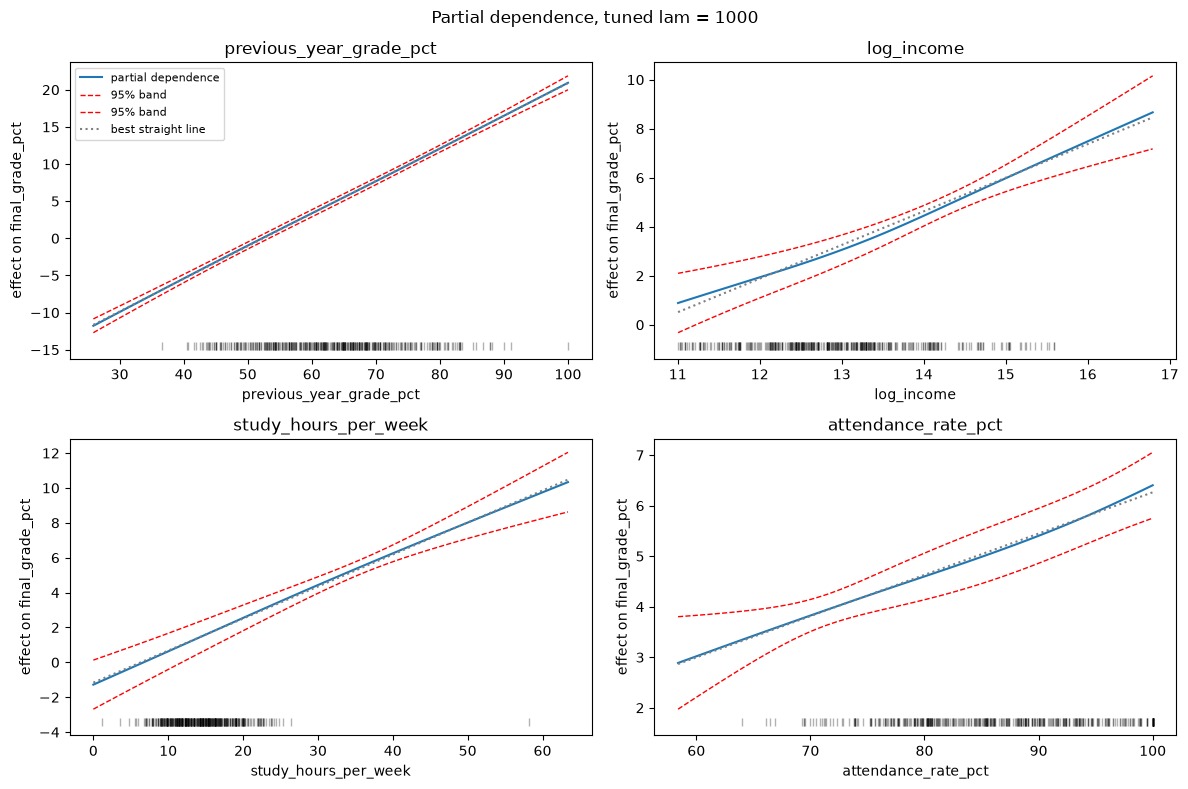

,predictor,slope of straight line,R2 of straight line vs curve,share of range with line inside 95% band
0,previous_year_grade_pct,0.439,1.000,1.0
1,log_income,1.372,0.995,1.0
2,study_hours_per_week,0.184,1.000,1.0
3,attendance_rate_pct,0.082,0.998,1.0


In [9]:
plot_partial_dependence(gam_tuned, f'Partial dependence, tuned lam = {best_lam:g}')

## GAM RMSE on the train/test split

RMSE is in grade points. The mean-only baseline predicts the training mean for every student, so it shows how much the GAM improves on guessing.

In [10]:
baseline = np.full_like(y_test, y_train.mean(), dtype=float)

rmse_table = pd.DataFrame({
    'train RMSE': [
        root_mean_squared_error(y_train, np.full_like(y_train, y_train.mean(), dtype=float)),
        root_mean_squared_error(y_train, gam.predict(X_train)),
        root_mean_squared_error(y_train, gam_tuned.predict(X_train)),
    ],
    'test RMSE': [
        root_mean_squared_error(y_test, baseline),
        root_mean_squared_error(y_test, gam.predict(X_test)),
        root_mean_squared_error(y_test, gam_tuned.predict(X_test)),
    ],
}, index=['Mean only (baseline)', 'GAM, lam = 0.6', f'GAM, tuned lam = {best_lam:g}']).round(3)
rmse_table

,train RMSE,test RMSE
Mean only (baseline),11.608,11.939
"GAM, lam = 0.6",9.411,10.142
"GAM, tuned lam = 1000",9.447,10.127


## 10-fold cross-validation

A single split can be lucky or unlucky, so here the data is split into 10 folds. Each fold takes a turn as the held-out set while the GAM is fitted on the other 9. The smoothing penalty `lam` is tuned with `gridsearch` on the 9 training folds only, so the held-out fold never influences the fit. The average of the 10 held-out RMSEs is the cross-validated RMSE.

In [11]:
from sklearn.model_selection import KFold

X_all = X_df.to_numpy(dtype=float)
y_all = y.to_numpy()
kfold = KFold(n_splits=10, shuffle=True, random_state=0)

fold_results = []
for fold, (train_idx, val_idx) in enumerate(kfold.split(X_all), start=1):
    gam_fold = make_gam(lam=0.6).gridsearch(X_all[train_idx], y_all[train_idx], lam=lam_grid, progress=False)
    fold_lam = gam_fold.terms[cont_idx[0]].lam[0]
    baseline_pred = np.full(len(val_idx), y_all[train_idx].mean())
    fold_results.append({
        'fold': fold,
        'best lam': fold_lam,
        'GAM RMSE': root_mean_squared_error(y_all[val_idx], gam_fold.predict(X_all[val_idx])),
        'Mean-only RMSE': root_mean_squared_error(y_all[val_idx], baseline_pred),
    })

fold_results = pd.DataFrame(fold_results).set_index('fold')
display(fold_results.round(3))

print(f"GAM cross-validated RMSE:       {fold_results['GAM RMSE'].mean():.3f}  (SD across folds {fold_results['GAM RMSE'].std():.3f})")
print(f"Mean-only cross-validated RMSE: {fold_results['Mean-only RMSE'].mean():.3f}  (SD across folds {fold_results['Mean-only RMSE'].std():.3f})")

,best lam,GAM RMSE,Mean-only RMSE
fold,,,
1,1000.0,9.621,11.424
2,1000.0,10.534,12.389
3,1000.0,9.891,11.603
4,1000.0,8.904,11.317
5,1000.0,9.080,11.467
6,1000.0,9.999,12.095
7,1000.0,9.630,11.549
8,1000.0,9.010,11.251
9,1000.0,9.218,11.649


GAM cross-validated RMSE:       9.570  (SD across folds 0.517)
Mean-only cross-validated RMSE: 11.655  (SD across folds 0.355)


## Comparison with OLS

OLS is fitted on exactly the same 10 folds, so each fold gives a GAM and an OLS RMSE on identical held-out students. OLS uses the same predictors, with the unordered categories one-hot encoded (first level dropped) and every other column entered as a straight line. Because the folds are shared, the two models are compared with a paired t-test on the per-fold RMSEs.

In [12]:
from scipy import stats
from sklearn.linear_model import LinearRegression

# OLS design matrix: continuous, discrete and ordinal columns as they are, nominal columns one-hot encoded
X_ols = pd.concat(
    [X_df.drop(columns=NOMINAL_COLS), pd.get_dummies(df[NOMINAL_COLS], drop_first=True)], axis=1
).to_numpy(dtype=float)

ols_rmse = []
for train_idx, val_idx in kfold.split(X_ols):          # same folds as the GAM (same KFold settings)
    ols = LinearRegression().fit(X_ols[train_idx], y_all[train_idx])
    ols_rmse.append(root_mean_squared_error(y_all[val_idx], ols.predict(X_ols[val_idx])))

comparison = fold_results[['GAM RMSE']].copy()
comparison['OLS RMSE'] = ols_rmse
comparison['GAM - OLS'] = comparison['GAM RMSE'] - comparison['OLS RMSE']
display(comparison.round(3))

diff = comparison['GAM - OLS']
t_stat, p_value = stats.ttest_rel(comparison['GAM RMSE'], comparison['OLS RMSE'])
print(f"GAM cross-validated RMSE: {comparison['GAM RMSE'].mean():.3f}  (SD {comparison['GAM RMSE'].std():.3f})")
print(f"OLS cross-validated RMSE: {comparison['OLS RMSE'].mean():.3f}  (SD {comparison['OLS RMSE'].std():.3f})")
print(f"Mean difference (GAM - OLS): {diff.mean():+.4f} grade points  (SD of differences {diff.std():.4f})")
print(f"GAM better in {(diff < 0).sum()} of 10 folds")
print(f"Paired t-test: t = {t_stat:.2f}, p = {p_value:.3f}")

,GAM RMSE,OLS RMSE,GAM - OLS
fold,,,
1,9.621,9.630,-0.009
2,10.534,10.513,0.021
3,9.891,9.884,0.007
4,8.904,8.930,-0.026
5,9.080,9.067,0.013
6,9.999,10.030,-0.031
7,9.630,9.597,0.032
8,9.010,8.981,0.029
9,9.218,9.199,0.019


GAM cross-validated RMSE: 9.570  (SD 0.517)
OLS cross-validated RMSE: 9.567  (SD 0.519)
Mean difference (GAM - OLS): +0.0034 grade points  (SD of differences 0.0234)
GAM better in 4 of 10 folds
Paired t-test: t = 0.46, p = 0.660


## How to read the results

- **Curves close to the dotted line (R² near 1)**: the effect is close to linear, so the GAM is not finding real nonlinearity for that predictor.
- **Curves that clearly bend away from the line**: that predictor has a nonlinear effect that a linear model would miss.
- **Wide bands at the ends**: there is little data there, so the shape at the extremes is uncertain.
- **Large `lam`**: the penalty forces the curves towards straight lines, so a large tuned value is itself a sign that the relationship is close to linear.

Partial dependence plots describe the fitted model, not causal effects, and they use the training data only (85% split, `random_state=0`).